In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.layers import Dense, SimpleRNN
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.preprocessing import MinMaxScaler

2024-04-14 00:57:20.958989: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-04-14 00:57:21.131724: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2024-04-14 00:57:21.131744: I tensorflow/compiler/xla/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2024-04-14 00:57:22.103833: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory
2024-

In [2]:
df = pd.read_csv('gazebo_dataset_synced.csv')

In [3]:
y = df.iloc[:,4:]
y

,theta0,theta1,theta2,theta3,theta4,theta5,theta6
0,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
1,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
2,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
3,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
4,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
...,...,...,...,...,...,...,...
95865,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95866,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95867,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95868,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176


In [4]:
X = df.iloc[:,1:4]
X

,x,y,z
0,0.479692,-0.115205,0.905620
1,0.479692,-0.115205,0.905620
2,0.479692,-0.115205,0.905620
3,0.479692,-0.115205,0.905620
4,0.479692,-0.115205,0.905620
...,...,...,...
95865,-0.154206,-0.471443,0.801403
95866,-0.154157,-0.471496,0.801452
95867,-0.154109,-0.471548,0.801501
95868,-0.154060,-0.471601,0.801549


In [5]:
X.shape

(95870, 3)

In [6]:
xscaler = MinMaxScaler()
yscaler = MinMaxScaler()
X_s = xscaler.fit_transform(X)
y_s = yscaler.fit_transform(y)

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_s, y_s, test_size=0.2, random_state=42)

In [8]:
# Reshape input to be 3D [samples, timesteps, features]
X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

In [9]:
X_train.shape

(76696, 1, 3)

In [11]:
# Define your RNN model architecture
model = Sequential()
model.add(SimpleRNN(128, activation='relu', input_shape=(1, 3)))
model.add(Dense(128, activation='relu'))
model.add(Dense(32, activation='linear'))
model.add(Dense(7))

# Compile model
model.compile(optimizer='adam', loss='mse', metrics='mae')

# Train model
history = model.fit(X_train, y_train, epochs=50, validation_split=0.2, verbose=1)

Epoch 1/50
1918/1918 [==============================] - 7s 3ms/step - loss: 0.0342 - mae: 0.1256 - val_loss: 0.0265 - val_mae: 0.1067
Epoch 2/50
1918/1918 [==============================] - 5s 3ms/step - loss: 0.0245 - mae: 0.1034 - val_loss: 0.0231 - val_mae: 0.1012
Epoch 3/50
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0214 - mae: 0.0951 - val_loss: 0.0208 - val_mae: 0.0927
Epoch 4/50
1918/1918 [==============================] - 5s 3ms/step - loss: 0.0191 - mae: 0.0888 - val_loss: 0.0198 - val_mae: 0.0937
Epoch 5/50
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0171 - mae: 0.0830 - val_loss: 0.0164 - val_mae: 0.0800
Epoch 6/50
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0159 - mae: 0.0789 - val_loss: 0.0155 - val_mae: 0.0769
Epoch 7/50
1918/1918 [==============================] - 5s 3ms/step - loss: 0.0150 - mae: 0.0762 - val_loss: 0.0148 - val_mae: 0.0766
Epoch 8/50
1918/1918 [==============================] - 5s 3ms

In [12]:
# Evaluate your model
loss = model.evaluate(X_test, y_test, verbose=0)
print('Test loss:', loss)

Test loss: [0.007004676386713982, 0.04967580363154411]


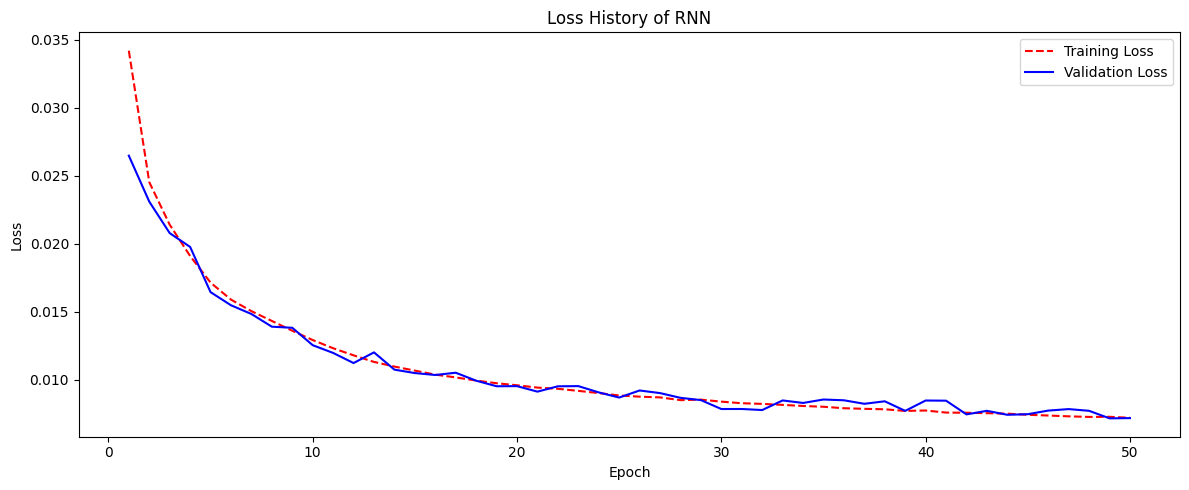

In [13]:
# Get training and validation loss histories
training_loss = history.history['loss']
validation_loss = history.history['val_loss']  # Corrected to 'val_loss'

# Create count of the number of epochs
epoch_count = range(1, len(training_loss)+1)

plt.figure(figsize=(12, 5))

#plt.subplot(111)
plt.plot(epoch_count, training_loss, 'r--')
plt.plot(epoch_count, validation_loss, 'b-')
plt.legend(['Training Loss', 'Validation Loss'])
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss History of RNN')

plt.tight_layout()
plt.show()

In [ ]:
# Use your model to predict joint angles from x, y, z coordinates
x_new = np.array([[0.5, 0, 0.4]])  # New x, y, z coordinates
x_new = xscaler.transform(x_new)  # Normalize
x_new = x_new.reshape((1, 1, 3))  # Reshape
y_new = model.predict(x_new)  # Predict
print('Predicted joint angles:', y_new)

In [ ]:
np.rad2deg(yscaler.inverse_transform(y_new))

In [ ]:
#tf.saved_model.save(model, 'RNN_model')


In [14]:
# equivalent to: model.save("model.h5")
from tensorflow.keras.models import save_model
save_model(model, "rnn_model.h5")


In [18]:
# load

# load and evaluate a saved model
from numpy import loadtxt
from tensorflow.keras.models import load_model
 
# load model
models = load_model('rnn_model.h5')
# summarize model.
models.summary()

# evaluate the model
score = models.evaluate(X_test, y_test, verbose=0)
print("%s: %.2f%%" % (models.metrics_names[1], score[1]*100))

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 simple_rnn_1 (SimpleRNN)    (None, 128)               16896     
                                                                 
 dense_3 (Dense)             (None, 128)               16512     
                                                                 
 dense_4 (Dense)             (None, 32)                4128      
                                                                 
 dense_5 (Dense)             (None, 7)                 231       
                                                                 
Total params: 37,767
Trainable params: 37,767
Non-trainable params: 0
_________________________________________________________________
mae: 4.97%


-
-